# Inelastic off-fault strain-rate and moment rate in California (NeoKinema model GCN2008088)

This notebook

1. reads the element strain-rate table `GCN2008088_element_strain_nanostrain_per_year.txt`;
2. computes and maps the **maximum horizontal shear strain rate**;
3. implements the **Savage & Simpson (1997)** method to convert each element's strain-rate tensor into a scalar **seismic moment rate**;

**Data source.** The strain rates come from the preferred kinematic finite-element model GCN2008088 of [Bird (2009)](https://doi.org/10.1029/2009JB006317). They are the per-element values of the NeoKinema output file `e_GCN2008088.nko` (units s⁻¹), converted to nanostrain/yr, together with the centroid coordinates of the triangular elements of the mesh `GCN8p9.feg`.

## 0. Setup

In [1]:
import hashlib
import os
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import pygmt
from pygmt.clib import Session

print("PyGMT", pygmt.__version__)
with Session() as lib:
    print("GMT  ", lib.info["version"])

# Paths for the self-contained supplement (run this notebook from Natgeo_supplements/Notebooks)
INPUT_DIR = Path("../Input_data/datasets/NeoKinema_Bird_2009")
OUTPUT_DIR = Path("../output_data/strain_analysis")
DATA_FILE = INPUT_DIR / "GCN2008088_element_strain_nanostrain_per_year.txt"
MESH_FILE = INPUT_DIR / "GCN8p9.feg"          # finite-element grid of the same model (used for element areas)
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TMP_DIR = Path(tempfile.mkdtemp(prefix="strain_analysis_"))  


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


INPUT_SHA256 = sha256(DATA_FILE)
INPUT_MTIME = DATA_FILE.stat().st_mtime
print("Input checksum (SHA-256):", INPUT_SHA256)

PyGMT v0.18.0
GMT   6.7.0
Input checksum (SHA-256): 9d5eda16a0166451e6ba8a956897f945e99a8863b4e3faeaa7bb42414b56e881


## 1. Read the strain-rate table

### Column definitions

| Column | Meaning | Units |
|---|---|---|
| `lon` | longitude of the element centroid (east positive, so western-US values are negative) | degrees |
| `lat` | latitude of the element centroid | degrees |
| `strain_1` | $\dot\varepsilon_{SS}$: normal strain rate along the **south** axis (equivalently N–S; the sign is the same because both indices flip) | nanostrain/yr |
| `strain_2` | $\dot\varepsilon_{SE}$: **tensor** (not engineering) shear strain-rate component in the south–east frame | nanostrain/yr |
| `strain_3` | $\dot\varepsilon_{EE}$: normal strain rate along the **east** axis | nanostrain/yr |

**Sign convention.** Extension is positive and shortening is negative.

**Coordinate frame.** NeoKinema works in spherical coordinates with colatitude $\theta$ (increasing to the south) and longitude $\phi$ (increasing to the east). So $S \equiv \theta$ and $E \equiv \phi$. In the source code (`SUBROUTINE E_rate` in `NeoKinema_v2p2_Guadalupe.f90`), component 2 includes the factor ½: $\dot\varepsilon_{\theta\phi}=\tfrac12(\partial_\theta u_\phi + \dots)$. That makes it the tensor component.

**Units.** 1 nanostrain/yr = $10^{-9}\,\mathrm{yr}^{-1}$ = $3.169\times10^{-17}\,\mathrm{s}^{-1}$ (with 1 yr = 365.25 d = 31 557 600 s). This is the year length that reproduces the `.nko` values; see the check below.

In [2]:
df = pd.read_csv(DATA_FILE, sep=r"\s+")
df = df.rename(columns={"strain_1": "e_ss", "strain_2": "e_se", "strain_3": "e_ee"})
print(df.shape)
df.head()

(12627, 5)


,lon,lat,e_ss,e_se,e_ee
0,-117.172337,31.468667,-13.980017,-2.758134,10.445566
1,-116.518000,31.772000,-24.993619,-15.589454,21.743186
2,-115.095333,31.604000,-15.463224,6.658654,9.183262
3,-115.418903,31.595317,-16.851758,5.901271,8.993916
4,-116.006000,31.575000,-6.753326,-2.411001,10.855814


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
lon,12627.0,-117.231396,5.647779,-128.096337,-121.476000,-117.713330,-113.736902,-104.056267
lat,12627.0,38.326396,4.635845,30.278333,34.425222,37.629357,41.451667,49.235000
e_ss,12627.0,-8.310700,30.309937,-728.980560,-10.129990,-1.653618,0.343978,877.301280
e_se,12627.0,4.313544,24.878458,-646.930800,-0.686378,0.473364,4.638967,710.046000
e_ee,12627.0,7.902112,28.759946,-288.436464,0.111241,2.300549,9.656626,883.612800


### Validation checks on the input

In [4]:
assert list(df.columns) == ["lon", "lat", "e_ss", "e_se", "e_ee"]
assert len(df) == 12627, "expected 12,627 triangular elements of GCN8p9.feg"
assert df.notna().all().all(), "missing values"
assert df.lon.between(-180, 180).all() and df.lat.between(-90, 90).all()
print("Longitude range: %.2f to %.2f deg" % (df.lon.min(), df.lon.max()))
print("Latitude range : %.2f to %.2f deg" % (df.lat.min(), df.lat.max()))

# Cross-check the unit conversion against the original NeoKinema output (s^-1), if present.
NKO = INPUT_DIR / "e_GCN2008088.nko"
if NKO.exists():
    nko = pd.read_csv(NKO, sep=r"\s+", header=None, names=["ele", "cracking", "e1", "e2", "e3"])
    YEAR_S = 365.25 * 86400.0
    diff = np.abs(nko[["e1", "e2", "e3"]].to_numpy() * YEAR_S * 1e9 - df[["e_ss", "e_se", "e_ee"]].to_numpy()).max()
    print(f"Max |nko(s^-1) * yr * 1e9 - table| = {diff:.2e} nanostrain/yr  (yr = 365.25 d)")
    assert diff < 1e-6
    print(f"Elements containing active faults (continuum-only strain rates): {(nko.cracking == 'T').sum()}")

Longitude range: -128.10 to -104.06 deg
Latitude range : 30.28 to 49.23 deg
Max |nko(s^-1) * yr * 1e9 - table| = 1.14e-13 nanostrain/yr  (yr = 365.25 d)
Elements containing active faults (continuum-only strain rates): 4290


### Element areas from the finite-element mesh

The Savage & Simpson method needs the **area** $A$ of each element. The text file contains only centroids. The areas come from the triangle connectivity in `GCN8p9.feg`. Each element is a spherical triangle on a sphere of radius $R = 6371$ km, the planetary radius used by NeoKinema. Its area follows from the spherical excess, using the Van Oosterom & Strackee (1983) formula for unit vertex vectors $\mathbf a,\mathbf b,\mathbf c$:

$$
\tan\frac{E}{2} = \frac{|\mathbf a\cdot(\mathbf b\times\mathbf c)|}{1+\mathbf a\cdot\mathbf b+\mathbf b\cdot\mathbf c+\mathbf c\cdot\mathbf a},
\qquad A = E\,R^2 .
$$

**Validation.** Element order in the `.feg` file must match the table rows. We check this by recomputing the centroids, i.e. the arithmetic mean of the three vertex longitudes and latitudes.

In [5]:
R_EARTH = 6371.0e3  # m, as in NeoKinema


def read_feg(path):
    lines = Path(path).read_text().splitlines()
    n_nodes = int(lines[1].split()[0])
    nodes = np.array([[float(v) for v in ln.split()[1:3]] for ln in lines[2:2 + n_nodes]])
    n_ele = int(lines[2 + n_nodes].split()[0])
    tri = np.array([[int(v) for v in ln.split()[1:4]] for ln in lines[3 + n_nodes:3 + n_nodes + n_ele]]) - 1
    return nodes, tri


def unit_vectors(lon, lat):
    lo, la = np.radians(lon), np.radians(lat)
    return np.stack([np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)], axis=-1)


nodes, tri = read_feg(MESH_FILE)
P = unit_vectors(nodes[:, 0], nodes[:, 1])
a, b, c = P[tri[:, 0]], P[tri[:, 1]], P[tri[:, 2]]
num = np.abs(np.einsum("ij,ij->i", a, np.cross(b, c)))
den = 1 + np.einsum("ij,ij->i", a, b) + np.einsum("ij,ij->i", b, c) + np.einsum("ij,ij->i", c, a)
df["area_m2"] = 2 * np.arctan2(num, den) * R_EARTH**2

# --- validation ---
assert len(tri) == len(df)
dlon = np.abs(nodes[tri, 0].mean(axis=1) - df.lon).max()
dlat = np.abs(nodes[tri, 1].mean(axis=1) - df.lat).max()
print(f"{len(nodes)} nodes, {len(tri)} elements")
print(f"Max centroid mismatch: dlon = {dlon:.1e} deg, dlat = {dlat:.1e} deg")
assert dlon < 1e-6 and dlat < 1e-6, "element ordering in the mesh does not match the table"
assert (df.area_m2 > 0).all()
print("Element area: min %.1f, median %.1f, max %.1f km^2" % tuple(np.percentile(df.area_m2 / 1e6, [0, 50, 100])))
print("Total model area: %.3e km^2" % (df.area_m2.sum() / 1e6))

6452 nodes, 12627 elements
Max centroid mismatch: dlon = 4.3e-14 deg, dlat = 1.4e-14 deg
Element area: min 6.4, median 365.9, max 691.3 km^2
Total model area: 3.216e+06 km^2


## 2. Maximum horizontal shear strain rate

The horizontal strain-rate tensor of each element is

$$
\dot{\boldsymbol\varepsilon} = \begin{pmatrix}\dot\varepsilon_{SS} & \dot\varepsilon_{SE}\\ \dot\varepsilon_{SE} & \dot\varepsilon_{EE}\end{pmatrix}.
$$

Its principal (eigen) values are

$$
\dot\varepsilon_{1,2} = \frac{\dot\varepsilon_{SS}+\dot\varepsilon_{EE}}{2} \pm \sqrt{\left(\frac{\dot\varepsilon_{EE}-\dot\varepsilon_{SS}}{2}\right)^2+\dot\varepsilon_{SE}^2},
\qquad \dot\varepsilon_1 \ge \dot\varepsilon_2 .
$$

The **maximum horizontal shear strain rate** (tensor shear, on planes at 45° to the principal axes) is

$$
\boxed{\dot\gamma_{\max} = \frac{\dot\varepsilon_1-\dot\varepsilon_2}{2} = \sqrt{\left(\frac{\dot\varepsilon_{EE}-\dot\varepsilon_{SS}}{2}\right)^2+\dot\varepsilon_{SE}^2}}
\qquad [\text{nanostrain/yr} = 10^{-9}\,\text{yr}^{-1}].
$$

Note: some authors report the **engineering** shear strain rate $\dot\varepsilon_1-\dot\varepsilon_2 = 2\dot\gamma_{\max}$. That is twice the value mapped here. The quantity is invariant under rotation of the horizontal axes, so the S–E vs. N–E sign convention does not affect it.

In [6]:
mean_n = 0.5 * (df.e_ss + df.e_ee)
radius = np.sqrt((0.5 * (df.e_ee - df.e_ss)) ** 2 + df.e_se**2)
df["e1"] = mean_n + radius       # most extensional principal strain rate, nanostrain/yr
df["e2"] = mean_n - radius       # most compressional principal strain rate, nanostrain/yr
df["gamma_max"] = radius         # maximum horizontal (tensor) shear strain rate, nanostrain/yr

# --- validation: tensor invariants ---
assert np.allclose(df.e1 + df.e2, df.e_ss + df.e_ee)                       # trace
assert np.allclose(df.e1 * df.e2, df.e_ss * df.e_ee - df.e_se**2)          # determinant
assert (df.e1 >= df.e2).all() and (df.gamma_max >= 0).all()
# independent check with numpy eigenvalues
T = np.stack([np.stack([df.e_ss, df.e_se], -1), np.stack([df.e_se, df.e_ee], -1)], -2)
ev = np.linalg.eigvalsh(T)
assert np.allclose(ev[:, 1], df.e1) and np.allclose(ev[:, 0], df.e2)
print("Invariant and eigenvalue checks passed.")
df[["e1", "e2", "gamma_max"]].describe(percentiles=[0.05, 0.5, 0.95]).T

Invariant and eigenvalue checks passed.


,count,mean,std,min,5%,50%,95%,max
e1,12627.0,14.674653,38.666112,-80.851270,-2.843958,4.554240,58.799901,1271.600272
e2,12627.0,-15.083241,34.849493,-729.173763,-59.934086,-4.437775,1.871814,82.049760
gamma_max,12627.0,14.878947,33.485822,0.022021,0.472514,4.480806,56.531219,936.507338


### Map of the maximum horizontal shear strain rate

Each triangular element is drawn as a polygon filled by its value, using the true mesh geometry. The range spans more than five orders of magnitude, so the color scale is logarithmic.

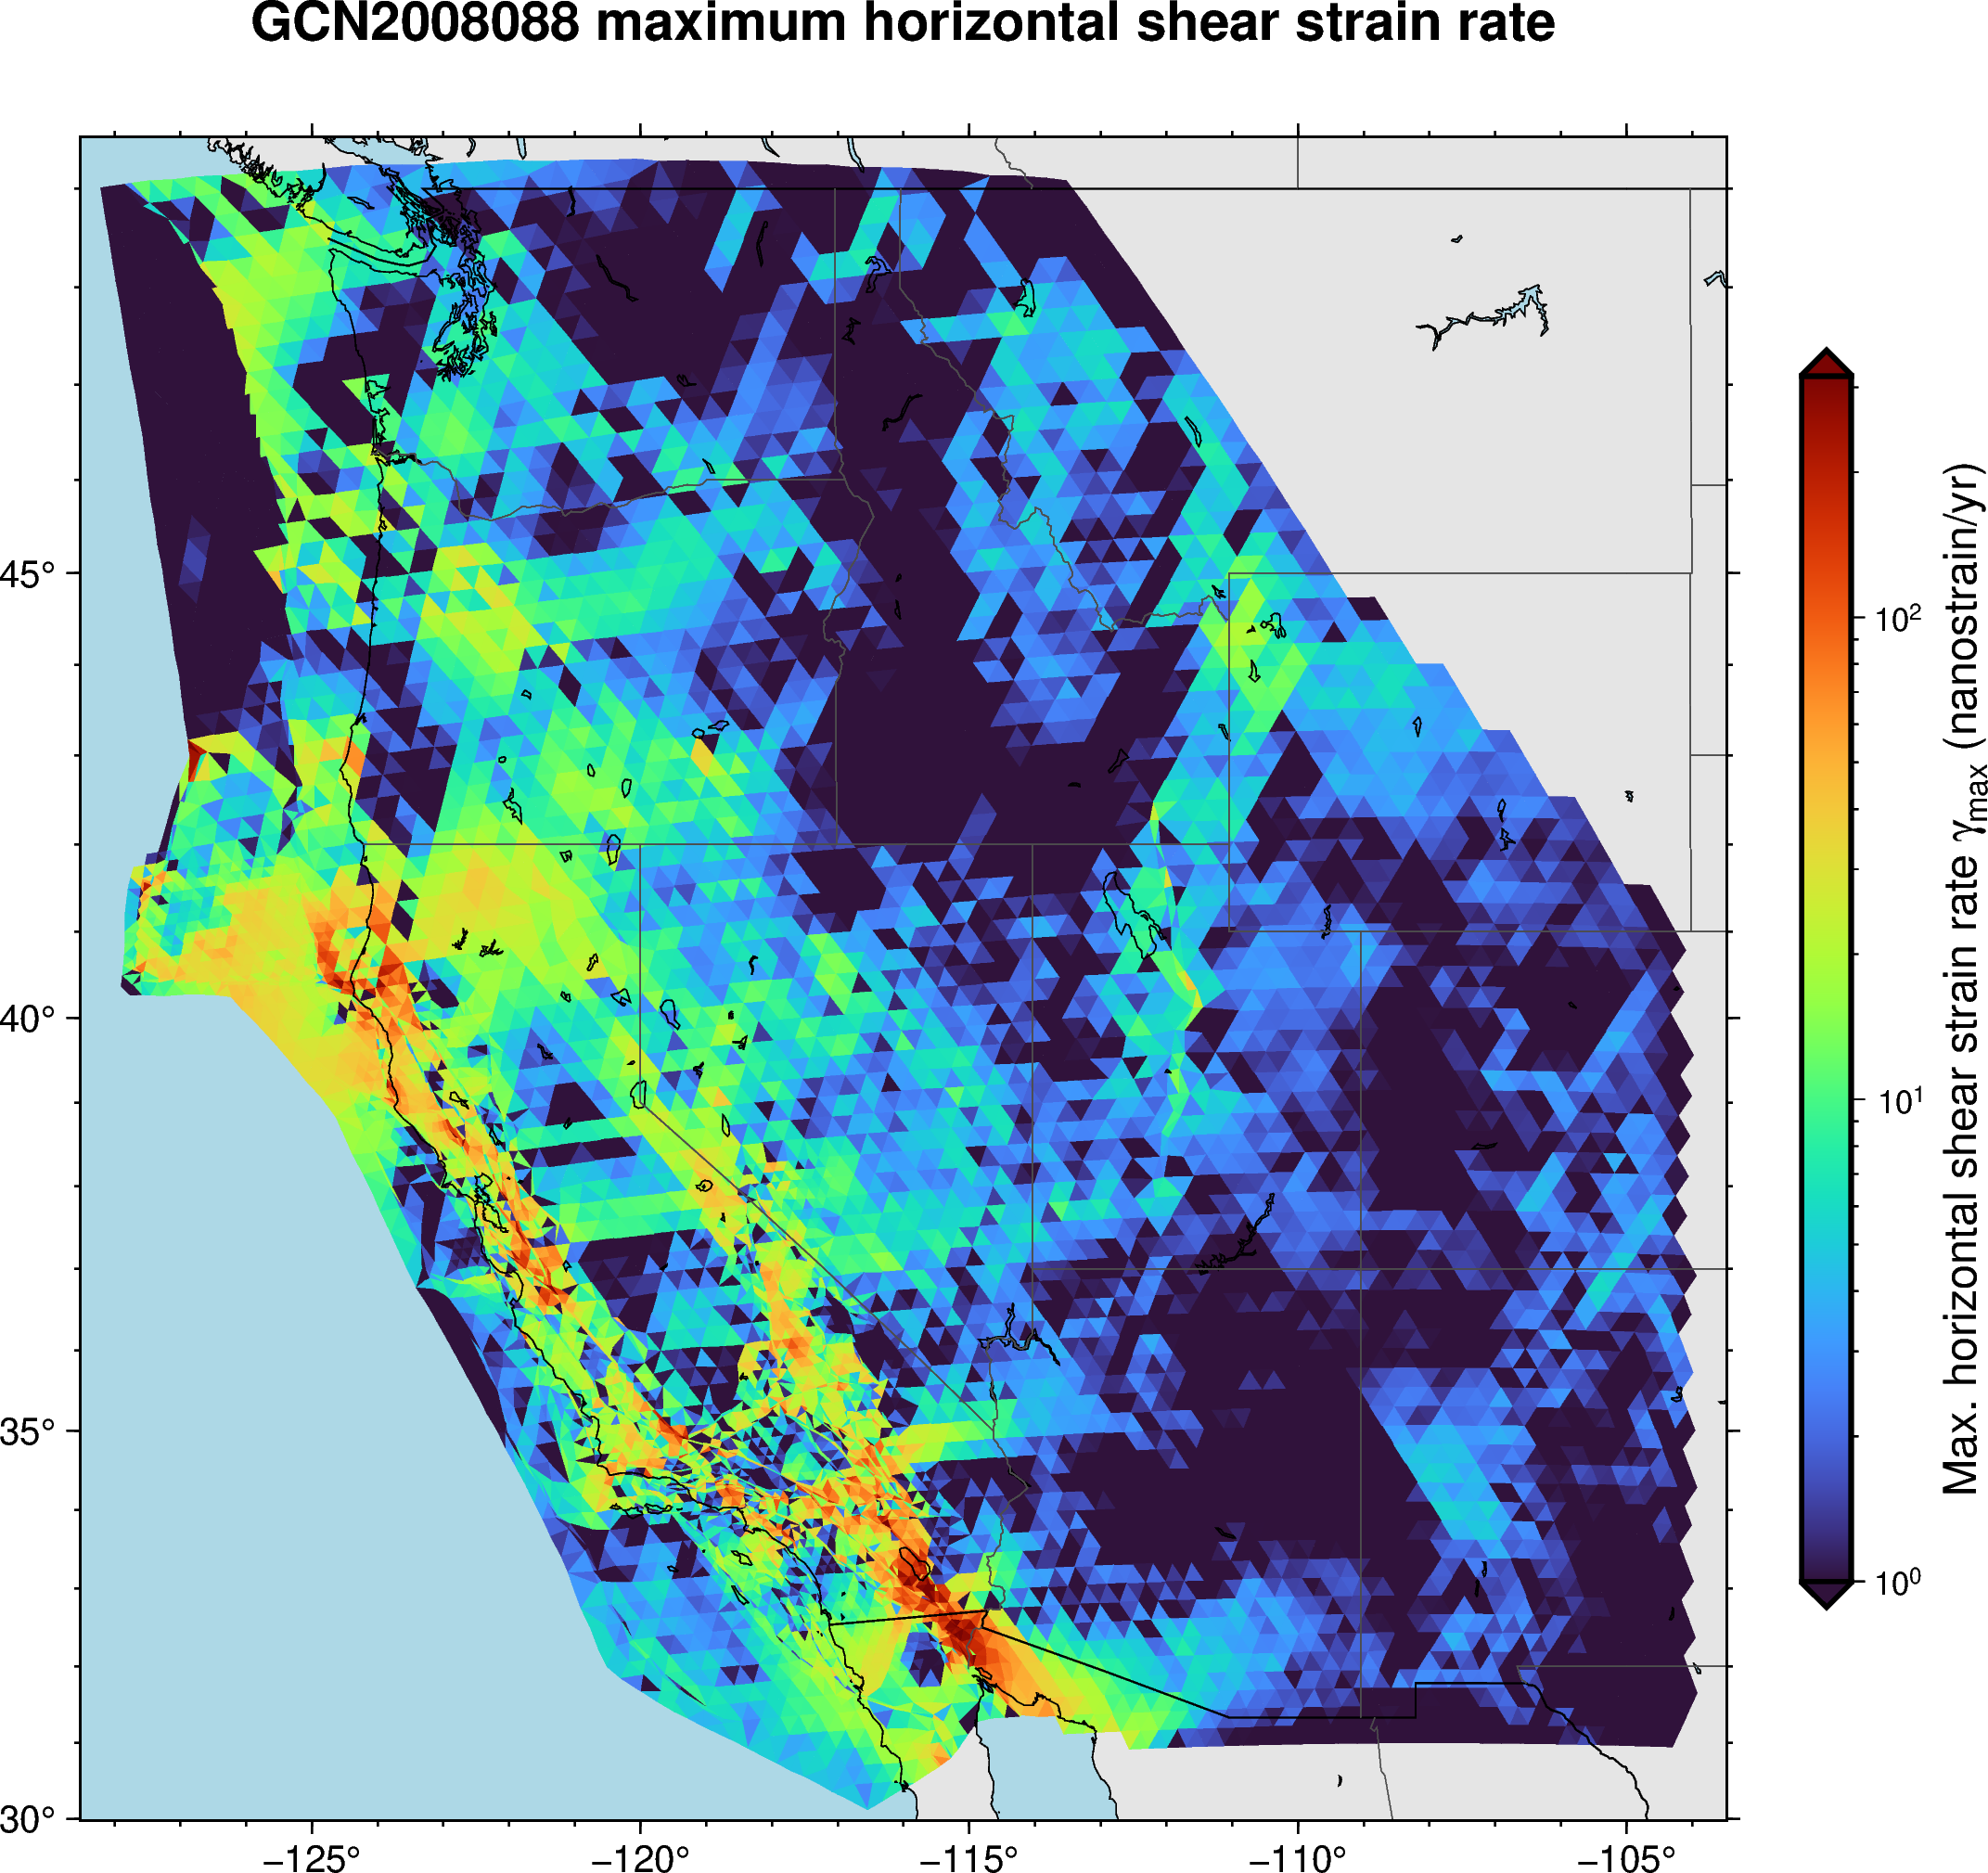

In [7]:
REGION = [-128.5, -103.5, 30, 49.5] # (lon_min, lon_max, lat_min, lat_max)
PROJ = "M15c"


def element_polygons(values, fname, mask=None):
    # Write each (selected) triangle as a closed GMT multi-segment polygon whose header carries -Z<value>.
    keep = np.ones(len(values), bool) if mask is None else np.asarray(mask)
    with open(fname, "w") as f:
        for k, v in enumerate(np.asarray(values)):
            if not keep[k]:
                continue
            f.write(f"> -Z{v:.6g}\n")
            for j in tri[k]:
                f.write(f"{nodes[j, 0]:.6f} {nodes[j, 1]:.6f}\n")
    return fname


def element_map(values, series, cmap, cb_label, title, outfile, reverse=False, extra=None):
    poly = element_polygons(values, TMP_DIR / "elements.gmt")
    fig = pygmt.Figure()
    pygmt.config(MAP_FRAME_TYPE="plain", FORMAT_GEO_MAP="ddd", FONT_TITLE="14p")
    fig.basemap(region=REGION, projection=PROJ, frame=[f"WSne+t{title}", "xa5f1", "ya5f1"])
    fig.coast(land="gray90", water="lightblue")
    pygmt.makecpt(cmap=cmap, series=series, reverse=reverse, continuous=True, log=True, background="o")  # series in log10 units
    fig.plot(data=str(poly), fill="+z", cmap=True, close=True)
    fig.coast(shorelines="0.3p,black", borders=["1/0.4p,black", "2/0.25p,gray30"])
    if extra:
        extra(fig)
    fig.colorbar(position="JMR+o0.7c/0c+w11c/0.45c+e", frame=["xa1pf3", f"x+l{cb_label}"], log=True)
    fig.savefig(FIG_DIR / outfile, dpi=200)
    return fig


fig = element_map(np.clip(df.gamma_max, 1e-2, None), [0, 2.5, 0.1], "turbo", "Max. horizontal shear strain rate @~g@~@-max@- (nanostrain/yr)",
                  "GCN2008088 maximum horizontal shear strain rate", "max_shear_strain_rate.png", reverse=False)
fig.show()

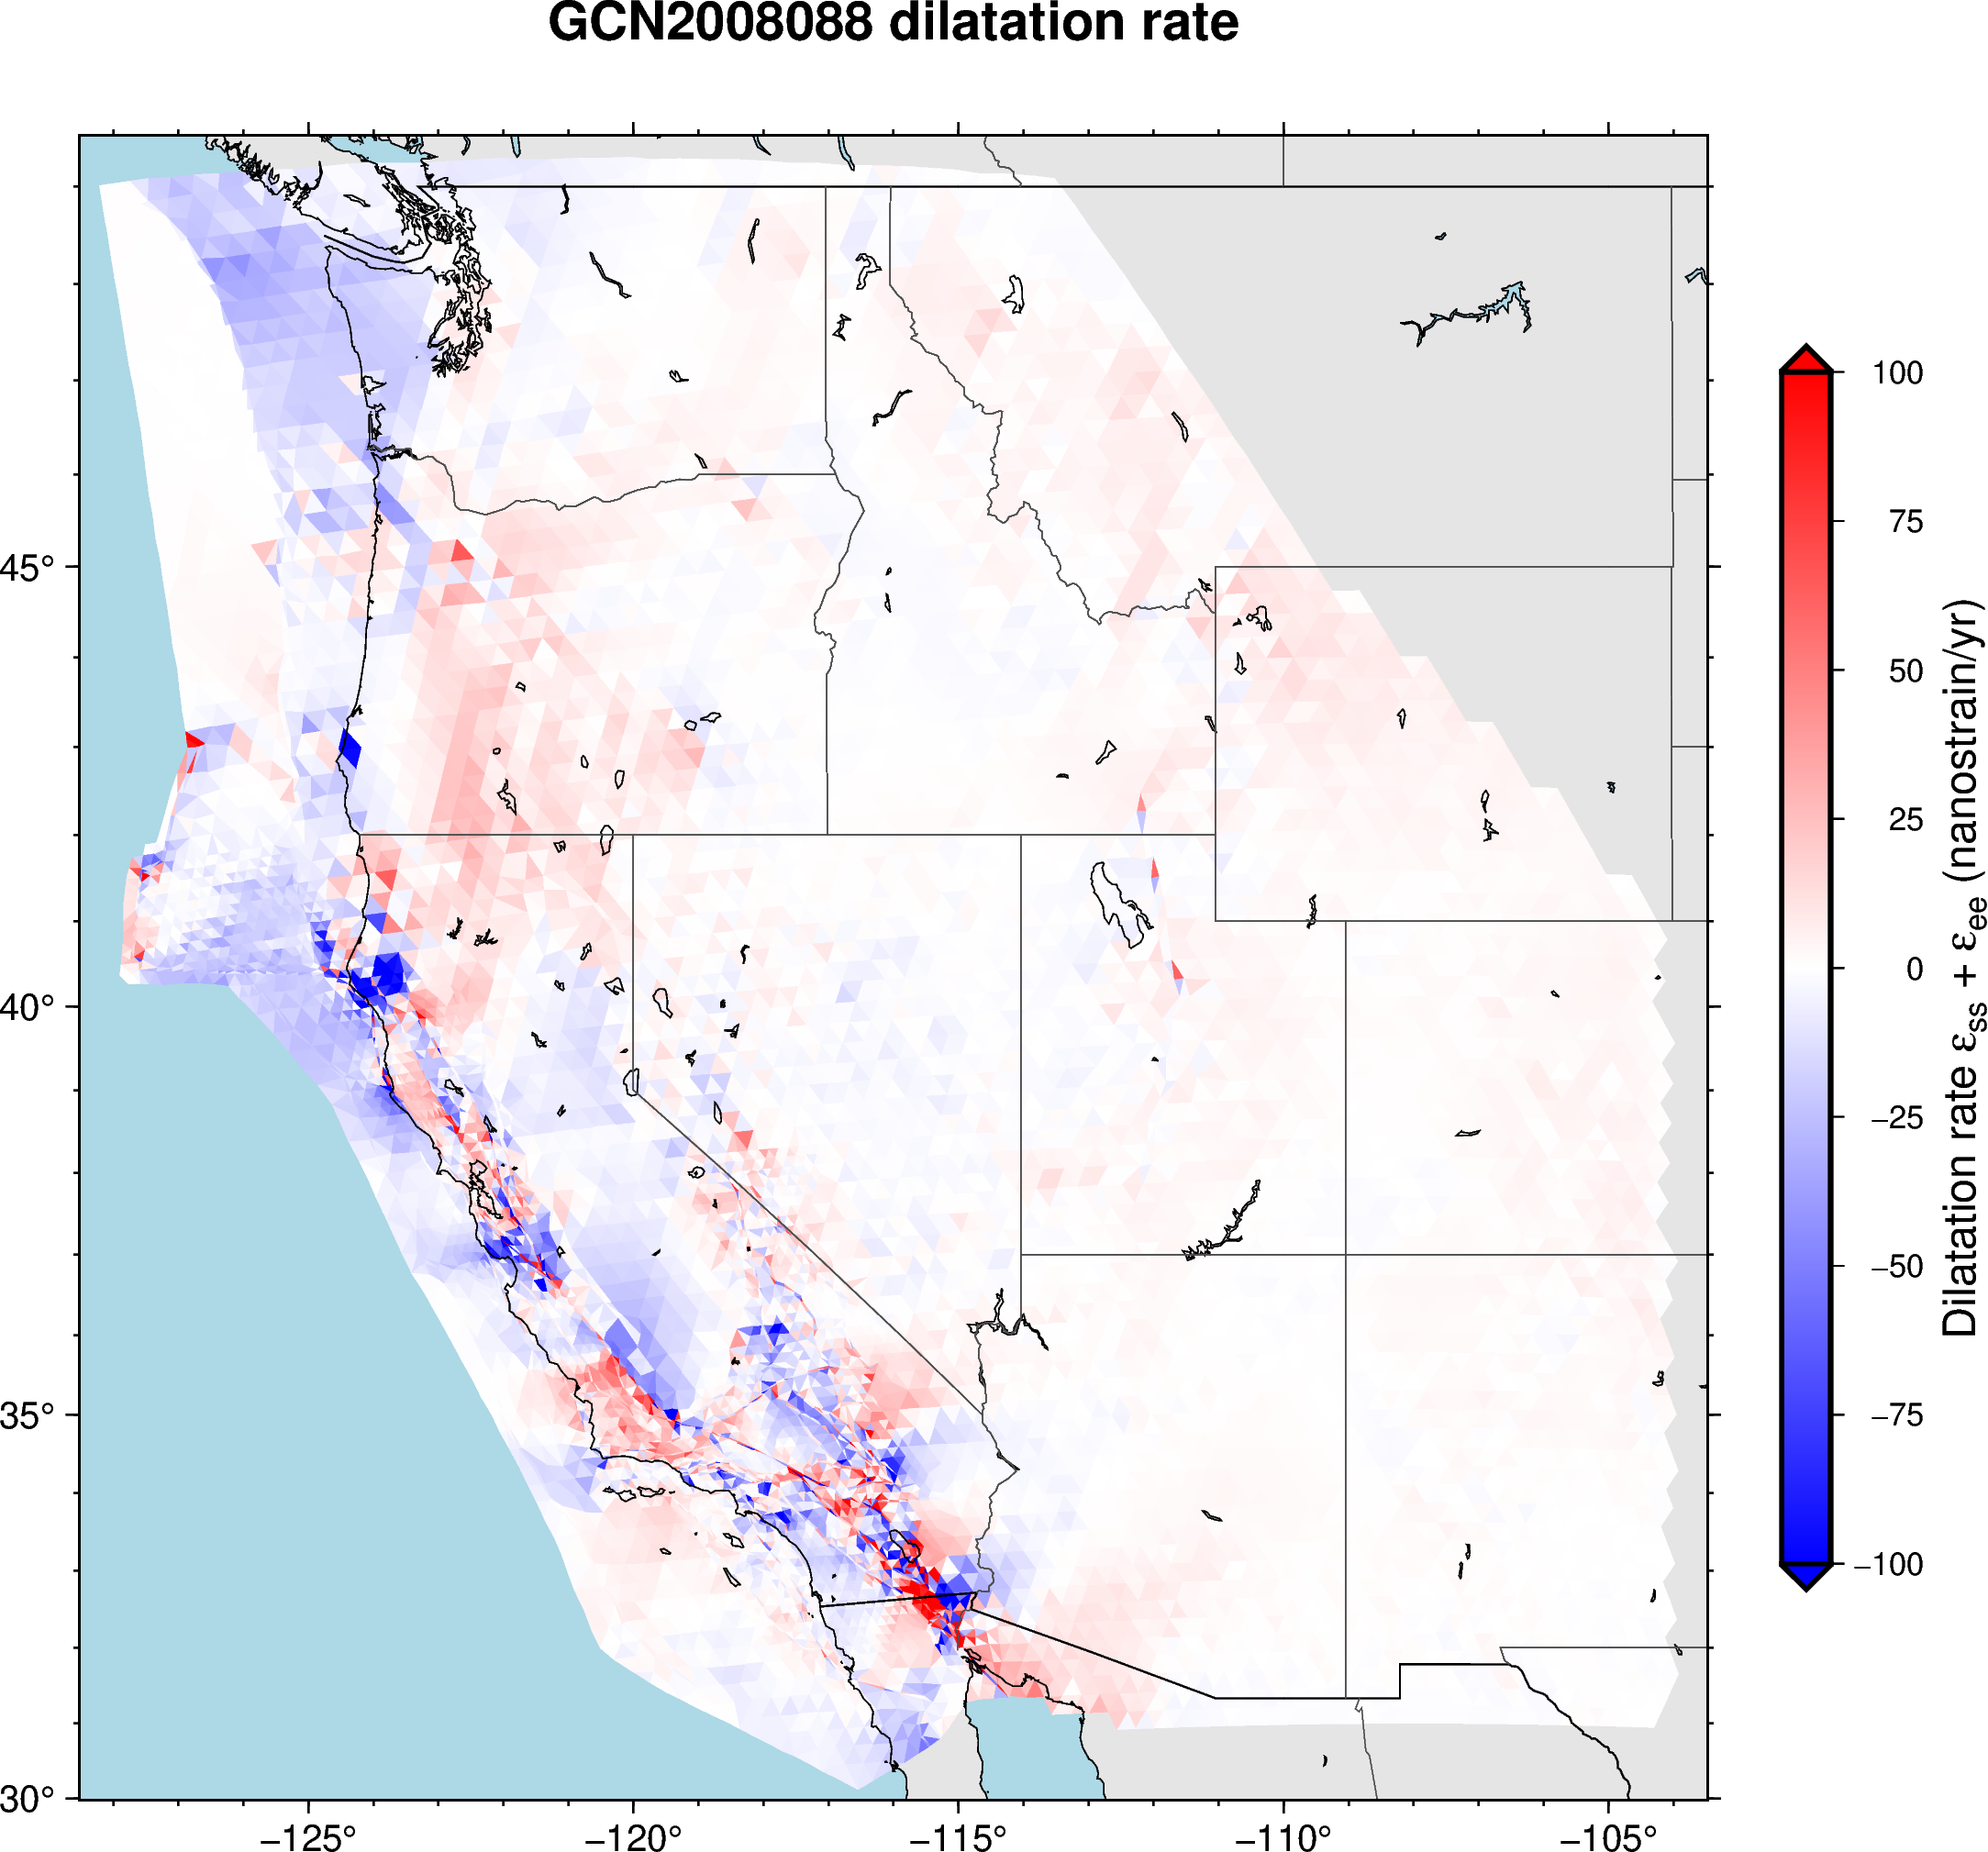

In [8]:
def plot_dilatation_rate(df, series=[-100, 100, 10], cmap="polar", cb_label="Dilatation rate @~e@~@-ss@- + @~e@~@-ee@- (nanostrain/yr)",
                      title="GCN2008088 dilatation rate", outfile="dilatation_rate.png"):
    values = df.e_ss + df.e_ee
    poly = element_polygons(values, TMP_DIR / "elements.gmt")
    fig = pygmt.Figure()
    pygmt.config(MAP_FRAME_TYPE="plain", FORMAT_GEO_MAP="ddd", FONT_TITLE="14p")
    fig.basemap(region=REGION, projection=PROJ, frame=[f"WSne+t{title}", "xa5f1", "ya5f1"])
    fig.coast(land="gray90", water="lightblue")
    pygmt.makecpt(cmap=cmap, series=series, continuous=True, background="o")
    fig.plot(data=str(poly), fill="+z", cmap=True, close=True)
    fig.coast(shorelines="0.3p,black", borders=["1/0.4p,black", "2/0.25p,gray30"])
    fig.colorbar(position="JMR+o0.7c/0c+w11c/0.45c+e", frame=["xa25f25", f"x+l{cb_label}"])
    fig.savefig(FIG_DIR / outfile, dpi=200)
    return fig

fig = plot_dilatation_rate(df)
fig.show()

In [9]:
e_xx = df.e_ee          # east
e_xy = -df.e_se         # east–north = −(south–east), I realized I needed to flip the sign after checking the principal strain rate directions were opposite to what I expected (see 1_strain_analysis.ipynb, where I compared our results with Bird 2009)
e_yy = df.e_ss          # north = south

df_to_save = pd.DataFrame({
    "Lon": df.lon,
    "Lat": df.lat,
    "Max_shear": 0.5 * np.sqrt((e_xx - e_yy)**2 + 4 * e_xy**2) * 1e-3,
    "Max_shear_std": 0.0,
    "Dilatation_rate": (e_xx + e_yy) * 1e-3,
    "Dilatation_rate_std": 0.0,
    "Exx_microstrain_yr": e_xx * 1e-3,
    "Exy_microstrain_yr": e_xy * 1e-3,
    "Eyy_microstrain_yr": e_yy * 1e-3,
    "Exx_std_microstrain_yr": 0.0,
    "Exy_std_microstrain_yr": 0.0,
    "Eyy_std_microstrain_yr": 0.0,
})

output_file = OUTPUT_DIR / "Bird_results_2009.csv"
df_to_save.to_csv(output_file, sep=' ', header=False, index=False, float_format="%.6e")
print(f"Results saved to {output_file}")

Results saved to ../output_data/strain_analysis/Bird_results_2009.csv


## 3. Seismic moment rate: Savage & Simpson (1997)

### Theory

Kostrov (1974) relates the moment rate tensor of the earthquakes in a volume $V$ to the strain rate: $\dot M_{ij} = 2\mu V \dot\varepsilon_{ij}$. Geodetic and kinematic models give only the horizontal strain rate. Savage & Simpson (1997) close the system by assuming that **seismogenic deformation is incompressible**:

$$
\dot\varepsilon_3 = -(\dot\varepsilon_1+\dot\varepsilon_2).
$$

Here $\dot\varepsilon_3$ is the vertical principal strain rate (one principal axis is assumed vertical). The scalar moment of a (double-couple) moment tensor is set by its largest-magnitude eigenvalue. That gives the **minimum scalar moment rate** compatible with the strain-rate tensor:

$$
\boxed{\dot M_0 = 2\,\mu\,H\,A\;\max\left(|\dot\varepsilon_1|,\;|\dot\varepsilon_2|,\;|\dot\varepsilon_1+\dot\varepsilon_2|\right)}
$$

with

| Symbol | Meaning | Value used | Units |
|---|---|---|---|
| $\mu$ | shear modulus (rigidity) of the seismogenic crust | $3.0\times10^{10}$ | Pa = N m⁻² |
| $H$ | seismogenic (brittle, fully coupled) thickness | $15$ km = $1.5\times10^{4}$ | m |
| $A$ | horizontal area of each finite element (from `GCN8p9.feg`, §1) | element-specific | m² |
| $\dot\varepsilon_{1,2}$ | horizontal principal strain rates (§2) | from table | yr⁻¹ (after ×10⁻⁹) |

**Unit conversion.**

$$
[\dot M_0] = \text{Pa}\cdot\text{m}\cdot\text{m}^2\cdot\text{yr}^{-1} = \text{N m yr}^{-1}, \qquad
\dot\varepsilon\,[\text{yr}^{-1}] = 10^{-9}\times\dot\varepsilon\,[\text{nanostrain/yr}],
$$

and for comparisons $1\ \text{N m yr}^{-1} = 1/31\,557\,600\ \text{N m s}^{-1}$.

**Moment magnitude equivalent.** For context we convert to $M_w = \tfrac23(\log_{10}\dot M_0 - 9.1)$ with $\dot M_0$ in N m (Hanks & Kanamori, 1979). This is the magnitude of a single earthquake per year that would release the same moment.

In [10]:
MU = 3.0e10            # Pa
H_SEIS = 15.0e3        # m
NANO = 1.0e-9          # nanostrain/yr -> 1/yr
YEAR_S = 365.25 * 86400.0


def savage_simpson(e1, e2, area_m2, mu=MU, H=H_SEIS):
    # Scalar seismic moment rate (N m / yr) of Savage & Simpson (1997); e1, e2 in nanostrain/yr.
    e_max = np.max(np.abs(np.stack([e1, e2, e1 + e2])), axis=0)
    return 2.0 * mu * H * area_m2 * e_max * NANO, e_max


def mw(m0):
    return 2.0 / 3.0 * (np.log10(m0) - 9.1)


df["M0dot"], df["e_max_ss"] = savage_simpson(df.e1.to_numpy(), df.e2.to_numpy(), df.area_m2.to_numpy())
df["M0dot_density"] = df.M0dot / (df.area_m2 / 1e6)     # N m yr^-1 km^-2

# Which principal strain controls the moment of each element?
which = np.argmax(np.abs(np.stack([df.e1, df.e2, df.e1 + df.e2])), axis=0)
print("Controlling term: |e1| (extension) %d, |e2| (shortening) %d, |e1+e2| (vertical) %d elements"
      % tuple(np.bincount(which, minlength=3)))

# --- validation ---
assert (df.M0dot >= 0).all()
k = df.M0dot.idxmax()
hand = 2 * MU * H_SEIS * df.area_m2[k] * max(abs(df.e1[k]), abs(df.e2[k]), abs(df.e1[k] + df.e2[k])) * 1e-9
assert np.isclose(hand, df.M0dot[k])
# Savage-Simpson moment must be >= the moment from max(|e1|,|e2|) alone (vertical term can only increase it)
assert (df.e_max_ss >= np.maximum(abs(df.e1), abs(df.e2)) - 1e-12).all()
print(f"Hand check on element {k}: {hand:.4e} N m/yr (matches)")
print(f"Whole model (all {len(df)} elements): M0dot = {df.M0dot.sum():.3e} N m/yr"
      f" = {df.M0dot.sum() / YEAR_S:.3e} N m/s   (Mw-equivalent {mw(df.M0dot.sum()):.2f} per yr)")

Controlling term: |e1| (extension) 5175, |e2| (shortening) 4481, |e1+e2| (vertical) 2971 elements
Hand check on element 7717: 7.8043e+16 N m/yr (matches)
Whole model (all 12627 elements): M0dot = 2.976e+19 N m/yr = 9.430e+11 N m/s   (Mw-equivalent 6.92 per yr)


### Map of moment-rate density

Element areas vary from about 6 to 700 km². The map therefore shows the moment rate **per unit area**, $\dot M_0/A$ (N m yr⁻¹ km⁻²), which does not depend on mesh resolution.

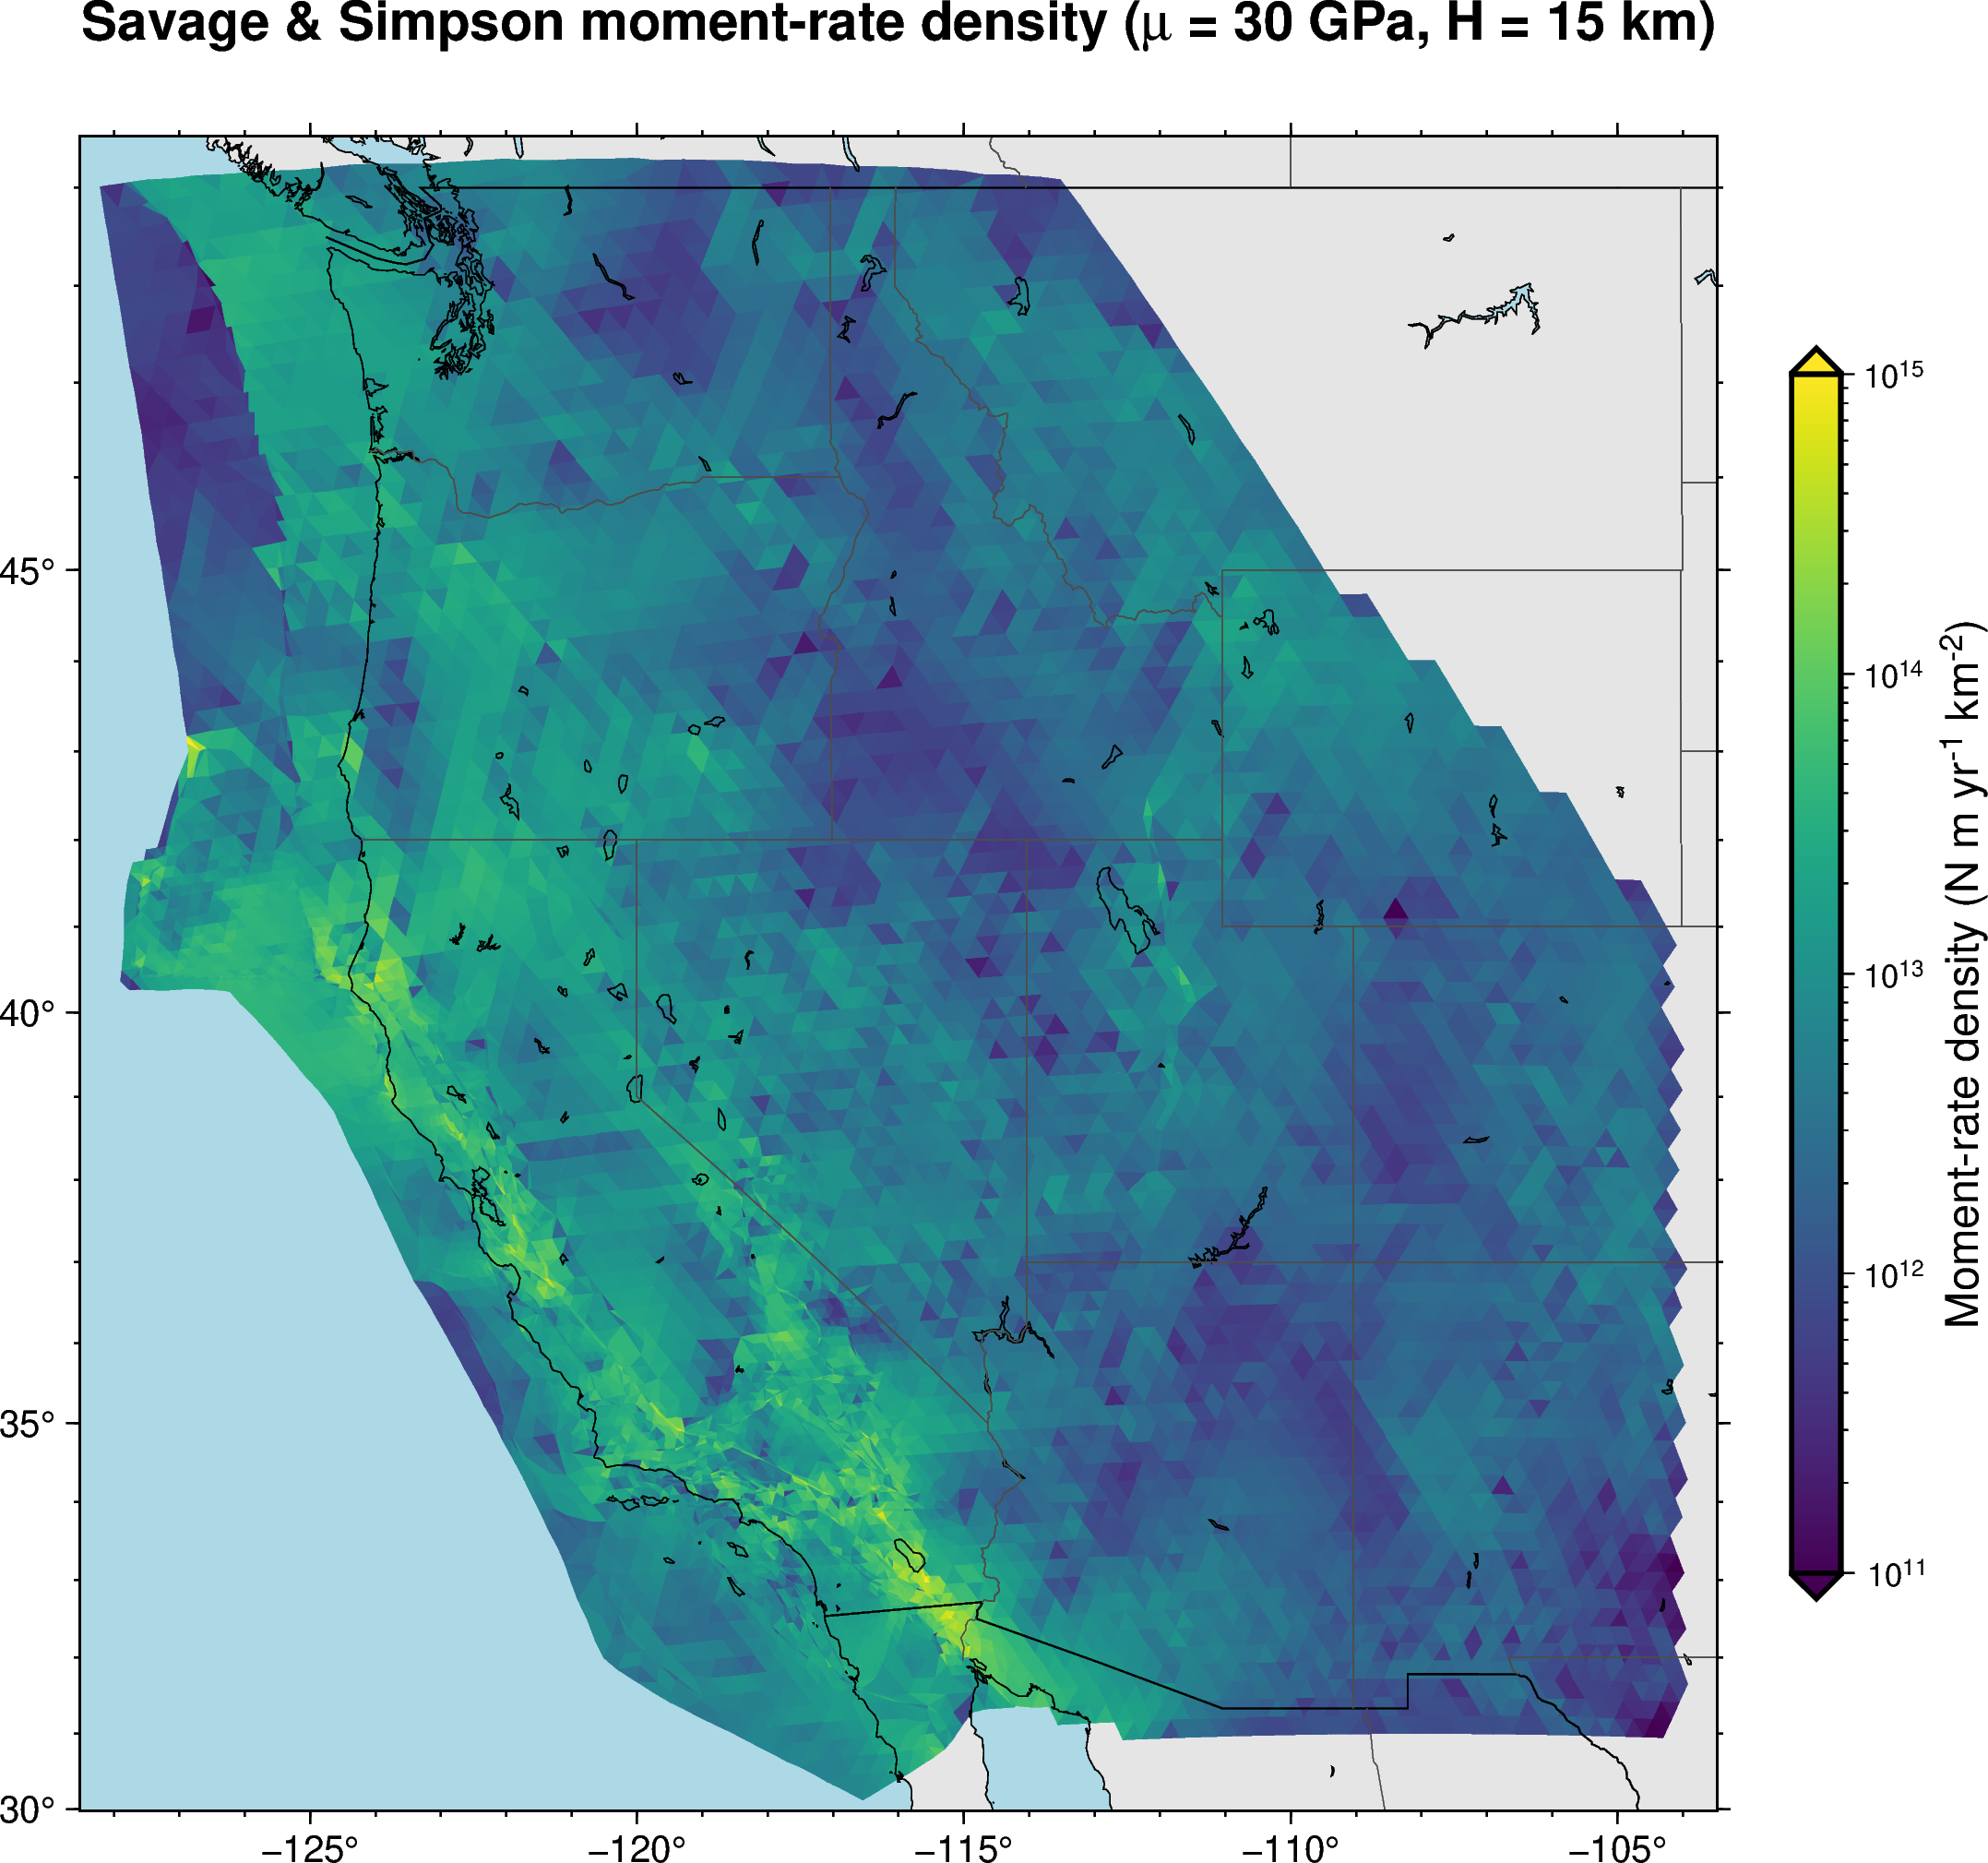

In [11]:
fig = element_map(np.clip(df.M0dot_density, 1e10, None), [11, 15, 0.1], "viridis", "Moment-rate density (N m yr@+-1@+ km@+-2@+)",
                  "Savage & Simpson moment-rate density (@~m@~ = 30 GPa, H = 15 km)", "moment_rate_density.png")
fig.show()

## 4. Off-fault moment rates in California

In [12]:
from pathlib import Path

import numpy as np
import pandas as pd
import pygmt
from matplotlib.path import Path as MplPath
from pyproj import Geod

# ============================================================
# 1. Read the custom California strain polygon
# ============================================================

ca_poly = Path("../Input_data/focal_mechanisms/California_strain_polygon.gmt")

if not ca_poly.exists():
    raise FileNotFoundError(f"Polygon file not found: {ca_poly.resolve()}")

california_polygon = np.loadtxt(
    ca_poly,
    dtype=float,
    usecols=(0, 1),
)

if california_polygon.ndim != 2 or california_polygon.shape[1] != 2:
    raise ValueError(
        "California_strain_polygon.gmt must contain two columns: lon lat"
    )

if len(california_polygon) < 3:
    raise ValueError("The polygon must contain at least three vertices")

if not np.isfinite(california_polygon).all():
    raise ValueError("The polygon contains NaN or infinite coordinates")

# Close the polygon if necessary
if not np.allclose(
    california_polygon[0],
    california_polygon[-1],
):
    california_polygon = np.vstack(
        [california_polygon, california_polygon[0]]
    )

# Retain these variables for plotting and validation
segments = [california_polygon]
allpts = california_polygon

print(
    f"California strain polygon: "
    f"{len(california_polygon) - 1} boundary edges"
)

print(
    "Polygon extent: "
    "lon %.3f to %.3f, lat %.3f to %.3f"
    % (
        allpts[:, 0].min(),
        allpts[:, 0].max(),
        allpts[:, 1].min(),
        allpts[:, 1].max(),
    )
)


# ============================================================
# 2. Select strain-element centroids inside the polygon
# ============================================================

required_columns = {"lon", "lat", "area_m2"}
missing_columns = required_columns.difference(df.columns)

if missing_columns:
    raise ValueError(
        f"df is missing required columns: {sorted(missing_columns)}"
    )

pts = pd.DataFrame(
    {
        "lon": df["lon"].to_numpy(),
        "lat": df["lat"].to_numpy(),
        "idx": np.arange(len(df), dtype=int),
    }
)

inside_df = pygmt.select(
    data=pts,
    polygon=str(ca_poly),
)

df["in_strain_polygon"] = False

if not inside_df.empty:
    selected_indices = (
        inside_df["idx"]
        .astype(int)
        .to_numpy()
    )

    df.loc[
        selected_indices,
        "in_strain_polygon",
    ] = True

# Mask used by the moment-rate cells below
df["in_CA"] = df["in_strain_polygon"]

print(
    "Elements with centroids inside the strain polygon: "
    f"{df['in_strain_polygon'].sum()} of {len(df)}"
)


# ============================================================
# 3. Independent point-in-polygon validation
# ============================================================

xy = df[["lon", "lat"]].to_numpy()

mpl_in = MplPath(
    california_polygon,
    closed=True,
).contains_points(xy)

gmt_in = df["in_strain_polygon"].to_numpy()

n_disagree = int(
    np.count_nonzero(mpl_in != gmt_in)
)

print(
    "GMT select vs. Matplotlib disagreements: "
    f"{n_disagree}"
)

# A small number of disagreements can occur for points located
# numerically on the polygon boundary.
if n_disagree > 5:
    print(
        "Warning: more than five point-selection disagreements "
        "were found. Inspect points close to the boundary."
    )


# ============================================================
# 4. Validate using known reference points
# ============================================================

tests = pd.DataFrame(
    {
        "lon": [
            -118.24,
            -122.42,
            -121.49,
            -119.77,
            -115.14,
            -119.81,
            -123.00,
            -116.00,
        ],
        "lat": [
            34.05,
            37.77,
            38.58,
            36.74,
            36.17,
            39.53,
            36.50,
            31.50,
        ],
        "name": [
            "Los Angeles",
            "San Francisco",
            "Sacramento",
            "Fresno",
            "Las Vegas NV",
            "Reno NV",
            "Pacific Ocean",
            "Baja California MX",
        ],
    }
)

test_input = tests[["lon", "lat"]].copy()
test_input["idx"] = np.arange(len(tests), dtype=int)

test_selection = pygmt.select(
    data=test_input,
    polygon=str(ca_poly),
)

selected_test_indices = set(
    test_selection["idx"].astype(int).tolist()
)

tests["inside"] = [
    i in selected_test_indices
    for i in range(len(tests))
]

display(tests)

expected = np.array(
    [True, True, True, True, False, False, False, False]
)

if not np.array_equal(
    tests["inside"].to_numpy(),
    expected,
):
    print(
        "Warning: the custom polygon did not produce all expected "
        "reference-point classifications."
    )


# ============================================================
# 5. Compare selected-element area with polygon area
# ============================================================

geod = Geod(ellps="WGS84")

polygon_area_m2, polygon_perimeter_m = (
    geod.polygon_area_perimeter(
        california_polygon[:, 0],
        california_polygon[:, 1],
    )
)

# The sign depends on clockwise/counterclockwise vertex order
polygon_area_km2 = abs(polygon_area_m2) / 1e6
polygon_perimeter_km = polygon_perimeter_m / 1e3

selected_area_km2 = (
    df.loc[
        df["in_strain_polygon"],
        "area_m2",
    ].sum()
    / 1e6
)

relative_area_difference = (
    abs(selected_area_km2 - polygon_area_km2)
    / polygon_area_km2
)

print(
    f"Custom polygon geodesic area: "
    f"{polygon_area_km2:,.0f} km²"
)

print(
    f"Custom polygon perimeter: "
    f"{polygon_perimeter_km:,.0f} km"
)

print(
    f"Centroid-selected element area: "
    f"{selected_area_km2:,.0f} km²"
)

print(
    f"Relative area difference: "
    f"{relative_area_difference:.2%}"
)

if relative_area_difference > 0.10:
    print(
        "Warning: the area difference exceeds 10%. "
        "Centroid selection counts intersecting elements as complete "
        "triangles or omits them completely. Exact results require "
        "clipping boundary triangles to the polygon."
    )


# ============================================================
# 6. Optional summary
# ============================================================

selection_summary = pd.Series(
    {
        "total_elements": len(df),
        "selected_elements": int(
            df["in_strain_polygon"].sum()
        ),
        "polygon_area_km2": polygon_area_km2,
        "selected_element_area_km2": selected_area_km2,
        "relative_area_difference": relative_area_difference,
        "gmt_matplotlib_disagreements": n_disagree,
    },
    name="value",
)

display(selection_summary.to_frame())

California strain polygon: 21 boundary edges
Polygon extent: lon -124.797 to -113.935, lat 32.122 to 42.072
Elements with centroids inside the strain polygon: 4956 of 12627
GMT select vs. Matplotlib disagreements: 0


,lon,lat,name,inside
0,-118.24,34.05,Los Angeles,True
1,-122.42,37.77,San Francisco,True
2,-121.49,38.58,Sacramento,True
3,-119.77,36.74,Fresno,True
4,-115.14,36.17,Las Vegas NV,False
5,-119.81,39.53,Reno NV,False
6,-123.00,36.50,Pacific Ocean,False
7,-116.00,31.50,Baja California MX,False


Custom polygon geodesic area: 520,103 km²
Custom polygon perimeter: 3,406 km
Centroid-selected element area: 519,265 km²
Relative area difference: 0.16%


,value
total_elements,12627.000000
selected_elements,4956.000000
polygon_area_km2,520103.404339
selected_element_area_km2,519264.774354
relative_area_difference,0.001612
gmt_matplotlib_disagreements,0.000000


### Border-effect bounds

The test is repeated on the three **vertices** of every element:

* **Lower bound**: elements with all 3 vertices inside California.
* **Upper bound**: elements with at least 1 vertex inside.

The centroid-based total should lie between the two.

In [13]:
nsel = pygmt.select(data=pd.DataFrame({"lon": nodes[:, 0], "lat": nodes[:, 1], "i": np.arange(len(nodes))}),
                    polygon=str(ca_poly))
node_in = np.zeros(len(nodes), bool)
node_in[nsel["i"].astype(int).to_numpy()] = True
n_in_vertices = node_in[tri].sum(axis=1)
lower = df.M0dot[n_in_vertices == 3].sum()
upper = df.M0dot[n_in_vertices >= 1].sum()
straddle = ((n_in_vertices > 0) & (n_in_vertices < 3)).sum()
print(f"Elements straddling the outline: {straddle}")

Elements straddling the outline: 348


### Total moment rate inside California

In [14]:
M0_CA = df.M0dot[df.in_CA].sum()
M0_all = df.M0dot.sum()

# for comparison only: a naive rectangular bounding box around California (NOT used for the result)
bx = [allpts[:, 0].min(), allpts[:, 0].max(), allpts[:, 1].min(), allpts[:, 1].max()]
in_box = df.lon.between(bx[0], bx[1]) & df.lat.between(bx[2], bx[3])
M0_box = df.M0dot[in_box].sum()

assert lower <= M0_CA <= upper
print(f"California (centroid point-in-polygon): {df.in_CA.sum()} elements")
print(f"  M0dot = {M0_CA:.3e} N m/yr = {M0_CA / YEAR_S:.3e} N m/s  (Mw-equivalent {mw(M0_CA):.2f} per yr)")
print(f"  border bounds: {lower:.3e} (all vertices in) to {upper:.3e} (any vertex in) N m/yr")
print(f"  share of whole-model moment rate: {100 * M0_CA / M0_all:.1f} %")
print(f"Bounding-box (for contrast only): {in_box.sum()} elements, {M0_box:.3e} N m/yr "
      f"(+{100 * (M0_box / M0_CA - 1):.0f} % overestimate from Nevada, Oregon, Baja and offshore)")

California (centroid point-in-polygon): 4956 elements
  M0dot = 1.361e+19 N m/yr = 4.312e+11 N m/s  (Mw-equivalent 6.69 per yr)
  border bounds: 1.295e+19 (all vertices in) to 1.424e+19 (any vertex in) N m/yr
  share of whole-model moment rate: 45.7 %
Bounding-box (for contrast only): 6276 elements, 1.645e+19 N m/yr (+21 % overestimate from Nevada, Oregon, Baja and offshore)


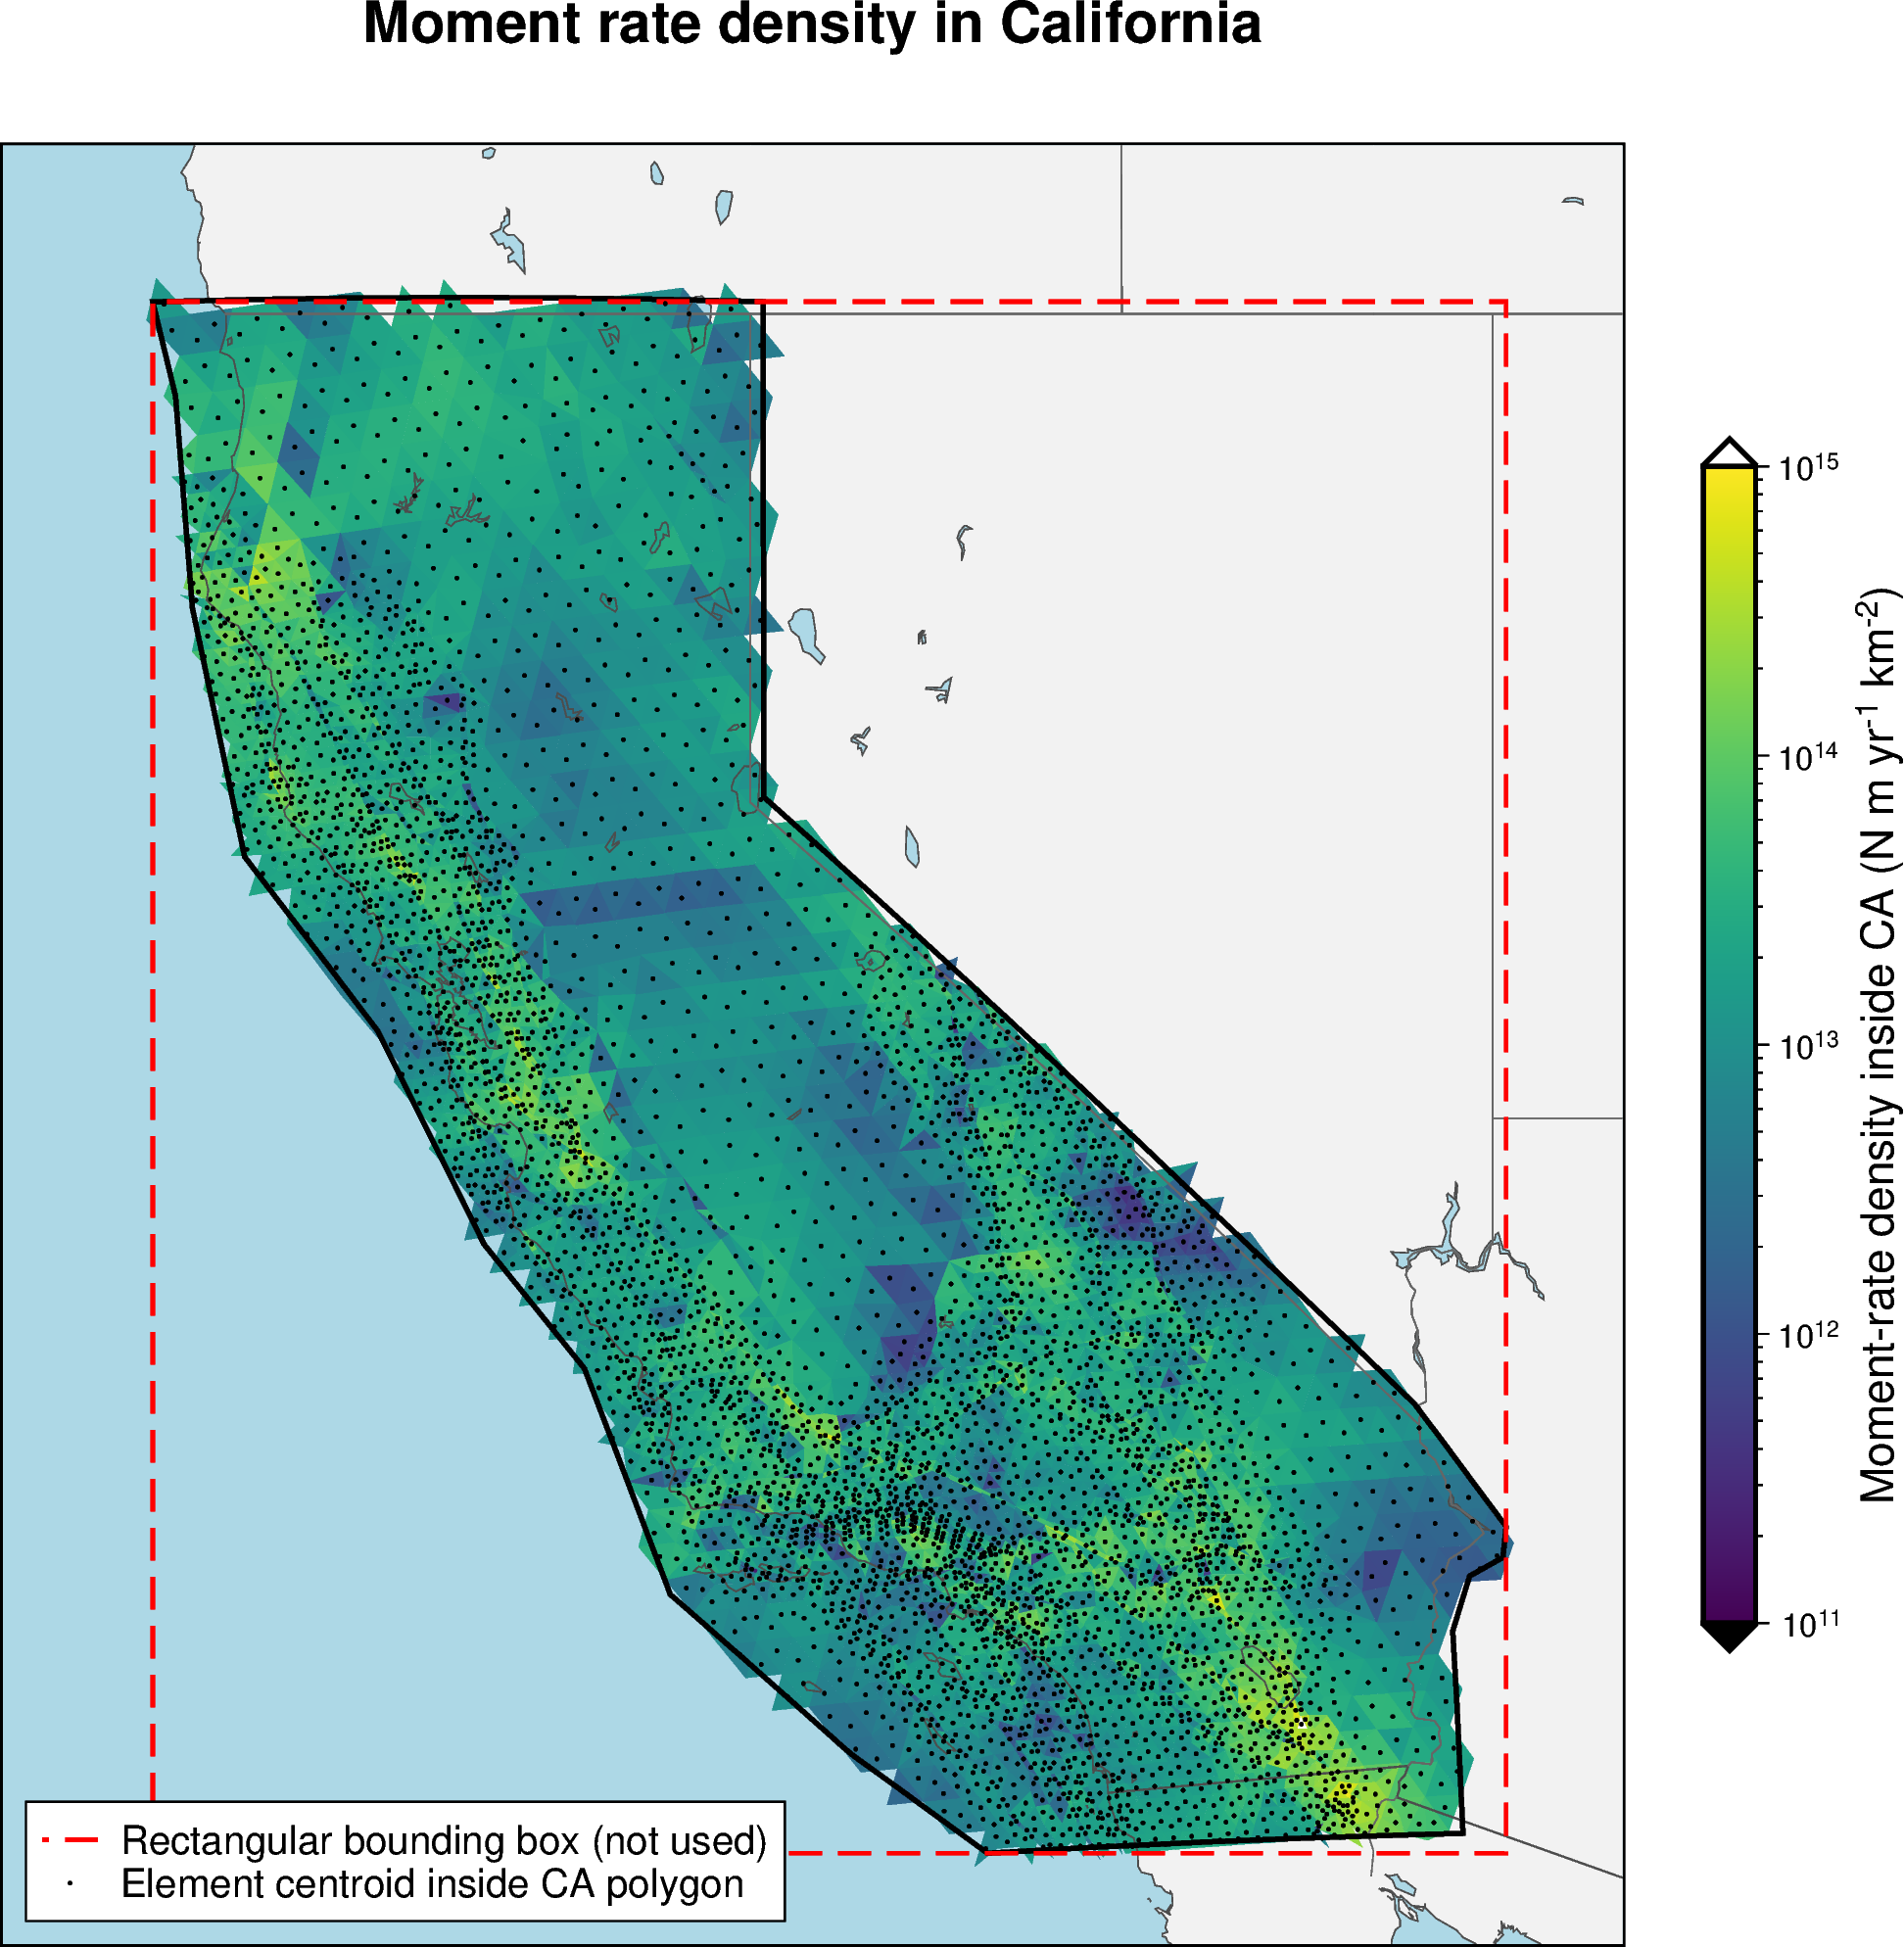

In [15]:
def ca_overlay(fig):
    fig.plot(data=str(ca_poly), pen="1.2p,black")
    fig.plot(x=[bx[0], bx[1], bx[1], bx[0], bx[0]], y=[bx[2], bx[2], bx[3], bx[3], bx[2]],
             pen="1p,red,dashed", straight_line="p", label="Rectangular bounding box (not used)")
    fig.plot(x=df.lon[df.in_CA], y=df.lat[df.in_CA], style="c0.04c", fill="black",
             label="Element centroid inside CA polygon")
    fig.legend(position="JBL+jBL+o0.2c", box="+gwhite+p0.5p")


# only the elements selected inside California are drawn
poly = element_polygons(np.clip(df.M0dot_density, 1e10, None), TMP_DIR / "elements_ca.gmt", mask=df.in_CA)
fig = pygmt.Figure()
pygmt.config(MAP_FRAME_TYPE="plain", FORMAT_GEO_MAP="ddd", FONT_TITLE="14p")
fig.basemap(region=[-126, -113, 31.5, 43], projection="M14c",
            frame=["WSne+tMoment rate density in California"])
fig.coast(land="gray95", water="lightblue")
pygmt.makecpt(cmap="viridis", series=[11, 15, 0.1], continuous=True, log=True)
fig.plot(data=str(poly), fill="+z", cmap=True, close=True)
fig.coast(shorelines="0.3p,gray30", borders=["1/0.4p,gray30", "2/0.3p,gray40"])
ca_overlay(fig)
fig.colorbar(position="JMR+o0.7c/0c+w10c/0.45c+e", frame=["xa1pf3", "x+lMoment-rate density inside CA (N m yr@+-1@+ km@+-2@+)"],
             log=True)
fig.savefig(FIG_DIR / "california_selection_moment_rate.png", dpi=200)
fig.show()

### Sensitivity to the elastic and seismogenic parameters

$\dot M_0$ is linear in $\mu$ and $H$, so the California total scales directly with them. The table gives values for commonly used choices.

In [16]:
rows = []
for mu in (3.0e10, 3.3e10):
    for H in (11e3, 12e3, 15e3, 20e3):
        m = savage_simpson(df.e1[df.in_CA].to_numpy(), df.e2[df.in_CA].to_numpy(), df.area_m2[df.in_CA].to_numpy(), mu, H)[0].sum()
        rows.append({"mu (GPa)": mu / 1e9, "H (km)": H / 1e3, "M0dot CA (N m/yr)": f"{m:.3e}", "Mw-equiv/yr": round(mw(m), 2)})
pd.DataFrame(rows)

,mu (GPa),H (km),M0dot CA (N m/yr),Mw-equiv/yr
0,30.0,11.0,9.980e+18,6.60
1,30.0,12.0,1.089e+19,6.62
2,30.0,15.0,1.361e+19,6.69
3,30.0,20.0,1.815e+19,6.77
4,33.0,11.0,1.098e+19,6.63
5,33.0,12.0,1.198e+19,6.65
6,33.0,15.0,1.497e+19,6.72
7,33.0,20.0,1.996e+19,6.80


## 5. Final checks and summary

In [17]:
summary = pd.Series({
    "Elements in model": len(df),
    "Elements in California (centroid in DCW polygon)": int(df.in_CA.sum()),
    "Area of selected elements (km^2)": f"{selected_area_km2:,.0f}",
    "Median max shear strain rate in CA (nanostrain/yr)": f"{df.gamma_max[df.in_CA].median():.1f}",
    "Shear modulus mu (Pa)": f"{MU:.1e}",
    "Seismogenic thickness H (m)": f"{H_SEIS:.1e}",
    "Moment rate inside California (N m/yr)": f"{M0_CA:.3e}",
    "Moment rate inside California (N m/s)": f"{M0_CA / YEAR_S:.3e}",
    "Border-effect range (N m/yr)": f"{lower:.2e} – {upper:.2e}",
    "Mw-equivalent per year": f"{mw(M0_CA):.2f}",
    "Fraction of whole-model moment rate": f"{100 * M0_CA / M0_all:.1f} %",
}, name="value")
summary.to_frame()

,value
Elements in model,12627
Elements in California (centroid in DCW polygon),4956
Area of selected elements (km^2),"519,265"
Median max shear strain rate in CA (nanostrain/yr),14.2
Shear modulus mu (Pa),3.0e+10
Seismogenic thickness H (m),1.5e+04
Moment rate inside California (N m/yr),1.361e+19
Moment rate inside California (N m/s),4.312e+11
Border-effect range (N m/yr),1.29e+19 – 1.42e+19
Mw-equivalent per year,6.69


### References

* Bird, P. (2009). Long-term fault slip rates, distributed deformation rates, and forecast of seismicity in the western United States from joint fitting of community geologic, geodetic, and stress direction data sets. *J. Geophys. Res.*, 114, B11403. https://doi.org/10.1029/2009JB006317